# Qwen3-4B QLoRA Fine-Tuning — Nourish Recipe Assistant

End-to-end pipeline that **actually trains and evaluates** a LoRA adapter on `Qwen/Qwen3-4B` using the Food.com `RAW_recipes.csv` dataset.

| Step | What happens |
|---|---|
| 1–2 | Config, environment & device detection (CUDA / Apple MPS / CPU) |
| 3–4 | Inspect and clean the raw data, save `data/processed/foodcom_cleaned.csv` |
| 5 | Rule-based dietary labelling (Vegan / Vegetarian / Eggitarian / Non-Vegetarian) with unit tests |
| 6 | Stratified 90 / 5 / 5 split, balanced training sample |
| 7 | Chat-template formatting (Qwen3, thinking disabled) + tokenization with **loss only on the assistant reply** |
| 8–9 | Load Qwen3-4B, attach LoRA, train with Hugging Face `Trainer` |
| 10 | Held-out test loss / perplexity: base vs fine-tuned |
| 11 | Generation eval on `diet_eval.jsonl`: dietary compliance, ingredient coverage, format — base vs fine-tuned |
| 12 | Reusable `generate_recipe()` + optional adapter merge |

**Run order:** set `SMOKE_TEST = True` first. It trains for a handful of steps on a tiny sample so you can confirm every cell works in minutes. Then set it to `False` for the real run.

**Configured for:** Windows 11, NVIDIA RTX 4070 (12 GB), 32 GB RAM. Qwen3-4B is loaded in 4-bit (QLoRA), which takes ~3 GB of VRAM and leaves room for batch size 2. Full run (6,000 recipes) is sized for **~1.5–2 hours** end to end; a live ETA prints after 3 steps.

**Before training, turn off the NVIDIA RAM fallback:** NVIDIA Control Panel → Manage 3D settings → *CUDA – Sysmem Fallback Policy* → **Prefer No Sysmem Fallback**. Otherwise, if VRAM fills up, Windows silently uses system RAM and training runs 10–50× slower instead of showing an error. A healthy step takes roughly 10–15 s; minutes per step means VRAM is spilling.

In [1]:
# One-time setup (uncomment and run once, then RESTART the kernel).
# Training needs an NVIDIA GPU (12 GB+ VRAM). Install the CUDA build of PyTorch first.
# %pip install torch --index-url https://download.pytorch.org/whl/cu128
# %pip install -U "transformers>=4.51" "peft>=0.13" "accelerate>=1.0" bitsandbytes scikit-learn pandas matplotlib

## 1 — Configuration

In [2]:
import os
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")   # less VRAM fragmentation

from pathlib import Path

MODEL_NAME = "Qwen/Qwen3-4B"

# Run from the repo root or from notebooks/ - paths resolve to the repo root either way.
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_DIR / "data" / "raw" / "RAW_recipes.csv"   # Food.com RAW_recipes.csv (see README)

PROCESSED_DATA_PATH = PROJECT_DIR / "data" / "processed" / "foodcom_cleaned.csv"
# diet_eval.jsonl: first existing location wins
EVAL_CANDIDATES = [PROJECT_DIR / "data" / "diet_eval.jsonl"]
EVAL_DATA_PATH  = next((p for p in EVAL_CANDIDATES if p.exists()), EVAL_CANDIDATES[0])
OUTPUT_ADAPTER_PATH = PROJECT_DIR / "models" / "qwen3-4b-recipe-lora"
CHECKPOINT_DIR      = PROJECT_DIR / "checkpoints" / "qwen3-4b-recipe-lora"
RESULTS_DIR         = PROJECT_DIR / "notebooks" / "results"
for p in (PROCESSED_DATA_PATH.parent, OUTPUT_ADAPTER_PATH, CHECKPOINT_DIR, RESULTS_DIR):
    p.mkdir(parents=True, exist_ok=True)

SEED = 42

# ---- Run size --------------------------------------------------------------
SMOKE_TEST = False          # True = tiny end-to-end check (minutes). False = real training run.

TRAIN_PER_DIET = 40   if SMOKE_TEST else 1500   # balanced: 4 diets x 1500 = 6,000 examples (~1.5-2 h total on RTX 4070)
VAL_SAMPLES    = 32   if SMOKE_TEST else 200
TEST_SAMPLES   = 32   if SMOKE_TEST else 200
MAX_STEPS      = 10   if SMOKE_TEST else -1     # -1 = run full NUM_EPOCHS
N_GEN_EVAL     = 4    if SMOKE_TEST else None   # None = all prompts in diet_eval.jsonl

# ---- Sequence / training hyper-parameters -----------------------------------
MAX_SEQ_LEN    = 640       # examples longer than this are dropped, not truncated
NUM_EPOCHS     = 1
PER_DEVICE_BATCH = 1       # batch 1 keeps VRAM well under 12 GB (no slow spill into system RAM)
GRAD_ACCUM     = 8 if SMOKE_TEST else 16       # effective batch = PER_DEVICE_BATCH * GRAD_ACCUM = 16
LEARNING_RATE  = 2e-4
WARMUP_FRACTION = 0.03
LOGGING_STEPS  = 1 if SMOKE_TEST else 10
EVAL_EVERY     = 5 if SMOKE_TEST else 125       # also the checkpoint interval

# ---- LoRA --------------------------------------------------------------------
LORA_R, LORA_ALPHA, LORA_DROPOUT = 16, 32, 0.05
LORA_TARGETS = ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]
USE_4BIT = True            # QLoRA: 4-bit base weights (~3 GB). Needed to fit training in 12 GB VRAM.

# ---- Generation --------------------------------------------------------------
GEN_MAX_NEW_TOKENS = 450
GEN_BATCH_SIZE     = 4

print("MODEL_NAME:", MODEL_NAME)
print("DATA_PATH :", DATA_PATH, "(found)" if DATA_PATH.exists() else "(NOT FOUND — fix DATA_PATH)")
print("EVAL_DATA :", EVAL_DATA_PATH, "(found)" if EVAL_DATA_PATH.exists() else "(not found — will use test-split prompts)")
print("SMOKE_TEST:", SMOKE_TEST)

MODEL_NAME: Qwen/Qwen3-4B
DATA_PATH : <project>/RAW_recipes.csv (found)
EVAL_DATA : <project>/data/diet_eval.jsonl (found)
SMOKE_TEST: False


## 2 — Environment & device

In [3]:
import sys, random, json, time, math, re, ast
import numpy as np
import pandas as pd
import torch, transformers, peft, accelerate
from packaging import version

print(f"Python       {sys.version.split()[0]}")
print(f"PyTorch      {torch.__version__}")
print(f"Transformers {transformers.__version__}")
print(f"PEFT         {peft.__version__}")
print(f"Accelerate   {accelerate.__version__}")
print(f"Pandas       {pd.__version__}")

if torch.cuda.is_available():
    DEVICE = "cuda"
    DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
    print(f"GPU: {torch.cuda.get_device_name(0)} "
          f"({torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB)")
elif torch.backends.mps.is_available():
    DEVICE = "mps"
    try:
        torch.ones(1, dtype=torch.bfloat16, device="mps") * 2
        DTYPE = torch.bfloat16
    except Exception:
        DTYPE = torch.float32
        print("bf16 not supported on this macOS/PyTorch build -> float32 (needs ~2x memory). "
              "macOS 14+ supports bf16 on MPS.")
    print("Apple Silicon GPU (MPS)")
else:
    DEVICE, DTYPE = "cpu", torch.float32
    print("!! No GPU found. PyTorch is probably the CPU-only build. Re-run the install cell with the\n"
          "!! CUDA index URL, restart the kernel, and check torch.cuda.is_available() is True.")

if USE_4BIT and DEVICE == "cuda":
    try:
        import bitsandbytes
        print(f"bitsandbytes {bitsandbytes.__version__}")
    except ImportError:
        raise ImportError("USE_4BIT=True needs bitsandbytes: %pip install -U bitsandbytes")

if USE_4BIT and DEVICE != "cuda":
    print("USE_4BIT needs CUDA; disabling.")
    USE_4BIT = False

print(f"DEVICE={DEVICE}  DTYPE={DTYPE}")

random.seed(SEED); np.random.seed(SEED); transformers.set_seed(SEED)

<project>/.venv/Lib/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1009 13:41:01.054000 25044 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


Python       3.14.8
PyTorch      2.11.0+cu128
Transformers 5.19.0
PEFT         0.21.2
Accelerate   1.15.0
Pandas       3.0.6
GPU: NVIDIA GeForce RTX 4070 (12.0 GB)
bitsandbytes 0.50.2
DEVICE=cuda  DTYPE=torch.bfloat16


## 3 — Inspect the dataset

In [4]:
df_raw = pd.read_csv(DATA_PATH)

print(f"Records: {len(df_raw):,}   Columns: {df_raw.shape[1]}")
print("Columns:", list(df_raw.columns))
missing = df_raw.isnull().sum()
print("\nMissing values:\n", missing[missing > 0].to_string())
print(f"\nDuplicate ids: {df_raw.duplicated(subset=['id']).sum()}")
print("\nminutes summary:\n", df_raw["minutes"].describe().to_string())
df_raw.head(3)

Records: 231,637   Columns: 12
Columns: ['name', 'id', 'minutes', 'contributor_id', 'submitted', 'tags', 'nutrition', 'n_steps', 'steps', 'description', 'ingredients', 'n_ingredients']

Missing values:
 name              1
description    4979

Duplicate ids: 0

minutes summary:
 count    2.316370e+05
mean     9.398546e+03
std      4.461963e+06
min      0.000000e+00
25%      2.000000e+01
50%      4.000000e+01
75%      6.500000e+01
max      2.147484e+09


,name,id,minutes,contributor_id,submitted,tags,nutrition,n_steps,steps,description,ingredients,n_ingredients
0,arriba baked winter squash mexican style,137739,55,47892,2005-09-16,"['60-minutes-or-less', 'time-to-make', 'course...","[51.5, 0.0, 13.0, 0.0, 2.0, 0.0, 4.0]",11,"['make a choice and proceed with recipe', 'dep...",autumn is my favorite time of year to cook! th...,"['winter squash', 'mexican seasoning', 'mixed ...",7
1,a bit different breakfast pizza,31490,30,26278,2002-06-17,"['30-minutes-or-less', 'time-to-make', 'course...","[173.4, 18.0, 0.0, 17.0, 22.0, 35.0, 1.0]",9,"['preheat oven to 425 degrees f', 'press dough...",this recipe calls for the crust to be prebaked...,"['prepared pizza crust', 'sausage patty', 'egg...",6
2,all in the kitchen chili,112140,130,196586,2005-02-25,"['time-to-make', 'course', 'preparation', 'mai...","[269.8, 22.0, 32.0, 48.0, 39.0, 27.0, 5.0]",6,"['brown ground beef in large pot', 'add choppe...",this modified version of 'mom's' chili was a h...,"['ground beef', 'yellow onions', 'diced tomato...",13


## 4 — Clean the data
Parses list columns, normalises whitespace/punctuation artefacts from Food.com, drops recipes with < 2 ingredients or steps and implausible cooking times, extracts a cuisine from the tags, and saves the cleaned set (list columns stored as JSON).

In [5]:
def parse_list_safe(val):
    if not isinstance(val, str):
        return []
    try:
        res = ast.literal_eval(val)
        if isinstance(res, (list, tuple)):
            return [str(x).strip() for x in res if str(x).strip()]
    except Exception:
        pass
    return []

def tidy_text(s: str) -> str:
    s = re.sub(r"\s+", " ", str(s)).strip()
    s = re.sub(r"\s+([,.;:!?)])", r"\1", s)      # "salt , pepper ." -> "salt, pepper."
    s = re.sub(r"\(\s+", "(", s)
    return s

def tidy_step(s: str) -> str:
    s = tidy_text(s)
    return s[:1].upper() + s[1:] if s else s

CUISINE_TAGS = [  # specific before general
    ("indian", "Indian"), ("thai", "Thai"), ("chinese", "Chinese"), ("japanese", "Japanese"),
    ("korean", "Korean"), ("vietnamese", "Vietnamese"), ("tex-mex", "Tex-Mex"), ("mexican", "Mexican"),
    ("italian", "Italian"), ("greek", "Greek"), ("french", "French"), ("spanish", "Spanish"),
    ("middle-eastern", "Middle Eastern"), ("moroccan", "Moroccan"), ("caribbean", "Caribbean"),
    ("german", "German"), ("cajun", "Cajun"), ("southern-united-states", "Southern US"),
    ("mediterranean", "Mediterranean"), ("asian", "Asian"), ("african", "African"),
    ("european", "European"), ("north-american", "American"), ("american", "American"),
]

def extract_cuisine(tags):
    tagset = set(tags)
    for tag, label in CUISINE_TAGS:
        if tag in tagset:
            return label
    return "General"

df = df_raw.drop_duplicates(subset=["id"]).copy()
after_dedup = len(df)

df["parsed_ingredients"] = df["ingredients"].apply(parse_list_safe).apply(lambda l: [tidy_text(x) for x in l])
df["parsed_steps"]       = df["steps"].apply(parse_list_safe).apply(lambda l: [tidy_step(x) for x in l if tidy_step(x)])
df["parsed_tags"]        = df["tags"].apply(parse_list_safe)
df["clean_name"]         = df["name"].fillna("").map(tidy_text)
df["clean_description"]  = df["description"].fillna("").map(tidy_text)
df["cuisine"]            = df["parsed_tags"].apply(extract_cuisine)

valid = (
    (df["clean_name"].str.len() > 0)
    & (df["parsed_ingredients"].str.len() >= 2)
    & (df["parsed_steps"].str.len() >= 2)
    & (df["minutes"] > 0) & (df["minutes"] <= 2 * 24 * 60)   # drop 0-minute and absurd (e.g. 2^31) times
)
df_cleaned = df[valid].reset_index(drop=True)

out = df_cleaned[["id", "clean_name", "minutes", "cuisine", "clean_description"]].copy()
for col in ["parsed_ingredients", "parsed_steps", "parsed_tags"]:
    out[col] = df_cleaned[col].apply(json.dumps)
out.to_csv(PROCESSED_DATA_PATH, index=False)

print(f"Raw:                 {len(df_raw):,}")
print(f"After dedup:         {after_dedup:,}")
print(f"After validity rules:{len(df_cleaned):,}")
print(f"Saved -> {PROCESSED_DATA_PATH}")
print("\nCuisine distribution:\n", df_cleaned["cuisine"].value_counts().head(15).to_string())

Raw:                 231,637
After dedup:         231,637
After validity rules:227,406
Saved -> data\processed\foodcom_cleaned.csv

Cuisine distribution:
 cuisine
General           142198
American           29105
European            9986
Italian             7291
Mexican             6052
Southern US         5535
Asian               4880
Indian              2671
Greek               2244
French              2146
Chinese             1958
Middle Eastern      1901
African             1715
Caribbean           1560
Tex-Mex             1449


## 5 — Dietary classification

Each ingredient is checked **on its own** (so terms can't combine across ingredients) after stripping known false positives: plant milks/butters (*peanut butter, almond milk, coconut cream*), *butternut squash, cream of tartar, bean curd, oyster mushrooms, celery ribs, swiss chard, hamburger buns*, and anything prefixed *vegan / dairy-free / eggless*.

- **Vegan** — no meat/fish, eggs or dairy
- **Vegetarian** — dairy allowed, no eggs, no meat/fish
- **Eggitarian** — eggs present (dairy optional), no meat/fish
- **Non-Vegetarian** — any meat, poultry, fish/seafood, or animal-derived stocks/sauces/gelatin

The same function scores the model's generations in Section 11, so the unit tests below matter.

In [6]:
def _terms_regex(terms):
    terms = sorted(set(terms), key=len, reverse=True)
    alt = "|".join(re.escape(t).replace(r"\ ", r"[\s-]+") for t in terms)
    return re.compile(rf"\b(?:{alt})(?:e?s)?\b", re.IGNORECASE)

MEAT_TERMS = [
    "beef", "ground beef", "corned beef", "roast beef", "brisket", "veal", "pork", "pork chop", "bacon", "ham",
    "sausage", "pepperoni", "prosciutto", "salami", "pancetta", "chorizo", "kielbasa", "bratwurst", "hot dog",
    "frankfurter", "wiener", "bologna", "pastrami", "jerky", "spare rib", "spareribs", "short rib", "baby back rib",
    "meatball", "meat", "ground meat", "turkey", "goose", "quail", "cornish hen", "lamb", "mutton", "venison",
    "rabbit", "bison", "elk", "liver", "giblet", "oxtail", "tripe",
    "fish", "salmon", "tuna", "cod", "trout", "halibut", "tilapia", "catfish", "haddock", "snapper", "mahi mahi",
    "swordfish", "sardine", "mackerel", "herring", "anchovy", "anchovies", "shrimp", "prawn", "crab", "crabmeat",
    "lobster", "scallop", "clam", "mussel", "oyster", "squid", "calamari", "octopus", "crawfish", "crayfish",
    "caviar", "roe", "seafood", "shellfish", "bonito", "dashi",
    "gelatin", "gelatine", "jello", "jell-o", "marshmallow", "lard", "suet", "bone broth",
    "fish sauce", "oyster sauce", "worcestershire", "worcestershire sauce",
]
MEAT_EXTRA = [  # terms that need a negative look-ahead
    re.compile(r"\bchickens?\b(?![\s-]+(?:seasoning|flavou?r(?:ed|ing)?\s+seasoning))", re.I),
    re.compile(r"\bsteaks?\b(?![\s-]+(?:sauce|seasoning|spice))", re.I),
    re.compile(r"\bhamburgers?\b(?![\s-]+(?:buns?|rolls?|pickles?|dill|relish))", re.I),
    re.compile(r"\bgoats?\b(?![\s-]+(?:cheese|milk|yogh?urt))", re.I),
    re.compile(r"\bducks?\b(?![\s-]+sauce)", re.I),
]
EGG_TERMS = ["egg", "egg white", "egg yolk", "yolk", "mayonnaise", "mayo", "meringue", "aioli", "eggnog"]
DAIRY_TERMS = [
    "milk", "buttermilk", "condensed milk", "evaporated milk", "butter", "ghee", "cream", "sour cream",
    "heavy cream", "whipping cream", "half-and-half", "half and half", "cream cheese", "cheese", "cheddar",
    "mozzarella", "parmesan", "parmigiano", "romano", "pecorino", "ricotta", "feta", "swiss cheese", "provolone",
    "gouda", "monterey jack", "jack cheese", "colby", "brie", "camembert", "gorgonzola", "gruyere", "havarti",
    "muenster", "mascarpone", "cottage cheese", "queso", "velveeta", "yogurt", "yoghurt", "curd", "paneer",
    "ice cream", "whey", "casein", "kefir", "creme fraiche", "crème fraîche", "custard",
]

EXCEPTIONS = [re.compile(p, re.I) for p in [
    r"\b(?:peanut|almond|cashew|hazelnut|walnut|pecan|pistachio|macadamia|sunflower|sesame|pumpkin seed|soy|soya|"
    r"oat|rice|coconut|hemp|flax|apple|pear|cocoa|cacao|shea|nut|seed)[\s-]+"
    r"(?:butter|milk|cream|cheese|yogh?urt|creamer|beverage|meat)s?\b",
    r"\b(?:vegan|vegetarian|veggie|meatless|plant[\s-]?based|dairy[\s-]?free|non[\s-]?dairy|nondairy|"
    r"egg[\s-]?free|eggless)\s+\w+(?:[\s-]+\w+)?",
    r"\begg\s+replacer\b", r"\b(?:flax|chia)\s+eggs?\b",
    r"\bcream\s+of\s+tartar\b",
    r"\bbutter(?:nut)?\s+(?:beans?|lettuce|squash)\b",
    r"\bbean\s+curd\b",
    r"\boyster\s+mushrooms?\b",
    r"\bcelery\s+ribs?\b",
]]

CATEGORY_RES = {
    "meat":  [_terms_regex(MEAT_TERMS), *MEAT_EXTRA],
    "egg":   [_terms_regex(EGG_TERMS)],
    "dairy": [_terms_regex(DAIRY_TERMS)],
}

def detect_animal_products(items):
    found = {k: set() for k in CATEGORY_RES}
    for item in items:
        t = str(item).lower()
        for pat in EXCEPTIONS:
            t = pat.sub(" ", t)
        for cat, regs in CATEGORY_RES.items():
            for r in regs:
                found[cat].update(m.group(0).lower() for m in r.finditer(t))
    return found

def classify_items(items):
    f = detect_animal_products(items)
    if f["meat"]:  return "Non-Vegetarian"
    if f["egg"]:   return "Eggitarian"
    if f["dairy"]: return "Vegetarian"
    return "Vegan"

# Which outputs satisfy which request
ALLOWED = {
    "Vegan":          {"Vegan"},
    "Vegetarian":     {"Vegan", "Vegetarian"},
    "Eggitarian":     {"Vegan", "Vegetarian", "Eggitarian"},
    "Non-Vegetarian": {"Vegan", "Vegetarian", "Eggitarian", "Non-Vegetarian"},
}
DIETS = list(ALLOWED)

# ---- unit tests --------------------------------------------------------------
_TESTS = [
    (["peanut butter", "bananas"], "Vegan"),        (["almond milk", "rolled oats"], "Vegan"),
    (["butternut squash", "olive oil"], "Vegan"),   (["eggplant", "tomatoes"], "Vegan"),
    (["celery ribs", "carrots"], "Vegan"),          (["swiss chard", "garlic"], "Vegan"),
    (["cream of tartar", "sugar"], "Vegan"),        (["oyster mushrooms", "soy sauce"], "Vegan"),
    (["hamburger buns", "lettuce"], "Vegan"),       (["bean curd", "scallions"], "Vegan"),
    (["coconut cream", "mango"], "Vegan"),          (["vegan cream cheese", "bagel"], "Vegan"),
    (["butter", "flour"], "Vegetarian"),            (["goat cheese", "beets"], "Vegetarian"),
    (["sour cream", "potatoes"], "Vegetarian"),     (["eggs", "milk"], "Eggitarian"),
    (["mayonnaise", "cabbage"], "Eggitarian"),      (["egg substitute", "spinach"], "Eggitarian"),
    (["chicken broth", "rice"], "Non-Vegetarian"),  (["worcestershire sauce", "ketchup"], "Non-Vegetarian"),
    (["ground beef", "onion"], "Non-Vegetarian"),   (["sausages", "peppers"], "Non-Vegetarian"),
    (["anchovies", "capers"], "Non-Vegetarian"),    (["unflavored gelatin", "juice"], "Non-Vegetarian"),
]
failures = [(i, exp, classify_items(i)) for i, exp in _TESTS if classify_items(i) != exp]
assert not failures, f"Classifier test failures: {failures}"
print(f"All {len(_TESTS)} classifier tests passed.")

All 24 classifier tests passed.


In [7]:
df_cleaned["dietary_attribute"] = df_cleaned["parsed_ingredients"].apply(classify_items)
dist = df_cleaned["dietary_attribute"].value_counts()
print("--- Dietary distribution ---")
for d in DIETS:
    print(f"{d:15s} {dist.get(d, 0):>8,}  ({dist.get(d, 0) / len(df_cleaned):.1%})")

# Spot-check: random examples per class with the terms that triggered the label
for d in DIETS:
    print(f"\n[{d}]")
    for _, r in df_cleaned[df_cleaned.dietary_attribute == d].sample(3, random_state=SEED).iterrows():
        hits = {k: sorted(v) for k, v in detect_animal_products(r.parsed_ingredients).items() if v}
        print(f"  {r.clean_name[:45]:45s} | {', '.join(r.parsed_ingredients[:6])[:70]} | {hits}")

--- Dietary distribution ---
Vegan             37,323  (16.4%)
Vegetarian        43,995  (19.3%)
Eggitarian        46,954  (20.6%)
Non-Vegetarian    99,134  (43.6%)

[Vegan]
  summer heat                                   | mint sprig, ice cubes, vodka, midori melon liqueur, lime wedge, club s | {}
  kale salad with avocado for two               | kale, red onions, red peppers, green onions, olive oil, lemon juice | {}
  light syrup                                   | sugar, water | {}

[Vegetarian]
  kohlrabi for the novice                       | kohlrabi, carrot, honey, pecans, lemon juice, lemon zest | {'dairy': ['butter']}
  refreshing sweet potato salad                 | sweet potatoes, cilantro, lime, plain yogurt, honey, salt | {'dairy': ['yogurt']}
  easy cheese tomato melt                       | lowfat mozzarella cheese, tomatoes, whole wheat bread, italian seasoni | {'dairy': ['cheese', 'mozzarella']}

[Eggitarian]
  maple syrup spice bread bread machine         | raisins, 

## 6 — Train / validation / test split
90 / 5 / 5, stratified by diet, `seed=42`. Training then uses a **diet-balanced** sample so the model sees as many Vegan and Eggitarian recipes as Non-Vegetarian ones.

In [8]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(df_cleaned, test_size=0.10, random_state=SEED,
                                     stratify=df_cleaned["dietary_attribute"])
val_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=SEED,
                                   stratify=temp_df["dietary_attribute"])

print(f"Train pool: {len(train_df):,}   Val pool: {len(val_df):,}   Test pool: {len(test_df):,}")
assert set(train_df.id).isdisjoint(test_df.id) and set(train_df.id).isdisjoint(val_df.id)

Train pool: 204,665   Val pool: 11,370   Test pool: 11,371


## 7 — Instruction formatting & tokenization

**Task framing:** the user gives a *subset* (3–6) of the recipe's ingredients + a dietary preference + cuisine; the assistant returns the **complete** recipe (all ingredients, all steps, total time). This mirrors real use ("here's what I have") and avoids teaching the model to just echo the input list or cut recipes off after 4 steps.

Prompts are built with Qwen3's own chat template (`enable_thinking=False`) so training and inference see exactly the same tokens. Prompt tokens are masked with `-100`, so loss is computed **only on the assistant's reply**.

In [9]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
IM_END = "<|im_end|>"
IM_END_ID = tokenizer.convert_tokens_to_ids(IM_END)
EOS_IDS = list({IM_END_ID, tokenizer.eos_token_id} - {None})

SYSTEM_PROMPT = (
    "You are Nourish, a recipe assistant. Create safe, practical recipes from the user's ingredients. "
    "Follow the dietary preference strictly: Vegan = no meat, fish, eggs or dairy; "
    "Vegetarian = no meat, fish or eggs (dairy allowed); Eggitarian = no meat or fish (eggs and dairy allowed); "
    "Non-Vegetarian = no restrictions. Pantry staples (oil, salt, pepper, water, spices) may be added if they fit "
    "the preference. Answer in this format:\n"
    "Recipe Name: ...\nDietary Preference: ...\nCuisine: ...\nTotal Time: ...\n"
    "Ingredients:\n- ...\n\nInstructions:\n1. ..."
)

def format_minutes(m):
    m = int(m)
    h, mm = divmod(m, 60)
    if h and mm: return f"{h} hr {mm} min"
    if h:        return f"{h} hr"
    return f"{mm} min"

def build_user_message(ingredients, preference, cuisine="General"):
    return (f"Ingredients I have: {', '.join(ingredients)}\n"
            f"Dietary preference: {preference}\n"
            f"Cuisine: {cuisine}\n"
            f"Create a complete recipe that uses these ingredients and strictly follows the dietary preference.")

def build_response(row):
    ings = "\n".join(f"- {i}" for i in row["parsed_ingredients"])
    steps = "\n".join(f"{n}. {s}" for n, s in enumerate(row["parsed_steps"], 1))
    return (f"Recipe Name: {row['clean_name'].title()}\n"
            f"Dietary Preference: {row['dietary_attribute']}\n"
            f"Cuisine: {row['cuisine']}\n"
            f"Total Time: {format_minutes(row['minutes'])}\n"
            f"Ingredients:\n{ings}\n\n"
            f"Instructions:\n{steps}")

def given_ingredients(row):
    """Deterministic (per recipe id) subset of 3-6 ingredients, kept in original order."""
    rng = random.Random(int(row["id"]))
    ings = row["parsed_ingredients"]
    k = min(len(ings), rng.randint(3, 6))
    idx = sorted(rng.sample(range(len(ings)), k))
    return [ings[i] for i in idx]

def chat_prompt(user_msg):
    messages = [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": user_msg}]
    return tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True,
                                         enable_thinking=False)

def tokenize_row(row):
    prompt = chat_prompt(build_user_message(given_ingredients(row), row["dietary_attribute"], row["cuisine"]))
    p_ids = tokenizer(prompt, add_special_tokens=False)["input_ids"]
    r_ids = tokenizer(build_response(row) + IM_END, add_special_tokens=False)["input_ids"]
    if len(p_ids) + len(r_ids) > MAX_SEQ_LEN:
        return None
    return {"input_ids": p_ids + r_ids, "labels": [-100] * len(p_ids) + r_ids}

def build_examples(frame, n, seed=SEED):
    """Tokenize shuffled rows until n examples fit in MAX_SEQ_LEN."""
    out = []
    for _, row in frame.sample(frac=1.0, random_state=seed).iterrows():
        ex = tokenize_row(row)
        if ex is not None:
            out.append(ex)
            if len(out) >= n:
                break
    return out

train_examples = []
for d in DIETS:
    pool = train_df[train_df.dietary_attribute == d]
    train_examples += build_examples(pool, TRAIN_PER_DIET)
random.Random(SEED).shuffle(train_examples)
val_examples  = build_examples(val_df, VAL_SAMPLES)
test_examples = build_examples(test_df, TEST_SAMPLES)

lens = [len(e["input_ids"]) for e in train_examples]
print(f"Train: {len(train_examples):,}  Val: {len(val_examples):,}  Test: {len(test_examples):,}")
print(f"Train token length  mean={np.mean(lens):.0f}  p95={np.percentile(lens, 95):.0f}  max={max(lens)}")

# Show one fully rendered training example (prompt + target)
ex_row = train_df.iloc[0]
print("\n================ EXAMPLE ================")
print(chat_prompt(build_user_message(given_ingredients(ex_row), ex_row['dietary_attribute'], ex_row['cuisine']))
      + build_response(ex_row) + IM_END)

Train: 6,000  Val: 200  Test: 200
Train token length  mean=400  p95=563  max=640

================ EXAMPLE ================
<|im_start|>system
You are Nourish, a recipe assistant. Create safe, practical recipes from the user's ingredients. Follow the dietary preference strictly: Vegan = no meat, fish, eggs or dairy; Vegetarian = no meat, fish or eggs (dairy allowed); Eggitarian = no meat or fish (eggs and dairy allowed); Non-Vegetarian = no restrictions. Pantry staples (oil, salt, pepper, water, spices) may be added if they fit the preference. Answer in this format:
Recipe Name: ...
Dietary Preference: ...
Cuisine: ...
Total Time: ...
Ingredients:
- ...

Instructions:
1. ...<|im_end|>
<|im_start|>user
Ingredients I have: dried parsley, dried sage, dried thyme, onion powder
Dietary preference: Vegan
Cuisine: General
Create a complete recipe that uses these ingredients and strictly follows the dietary preference.<|im_end|>
<|im_start|>assistant
<think>

</think>

Recipe Name: Simon And G

## 8 — Load Qwen3-4B and attach LoRA

In [10]:
from transformers import AutoModelForCausalLM
from peft import LoraConfig, TaskType, get_peft_model, prepare_model_for_kbit_training

dtype_kw = "dtype" if version.parse(transformers.__version__) >= version.parse("4.56") else "torch_dtype"
load_kwargs = {dtype_kw: DTYPE}
if DEVICE == "cuda":
    load_kwargs["device_map"] = "auto"
    if USE_4BIT:
        from transformers import BitsAndBytesConfig
        load_kwargs["quantization_config"] = BitsAndBytesConfig(
            load_in_4bit=True, bnb_4bit_quant_type="nf4",
            bnb_4bit_compute_dtype=DTYPE, bnb_4bit_use_double_quant=True)

t0 = time.time()
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, **load_kwargs)
if DEVICE != "cuda":
    model.to(DEVICE)
print(f"Loaded {MODEL_NAME} in {time.time() - t0:.0f}s")

model.config.use_cache = False
if USE_4BIT:
    model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=True)
else:
    model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
    model.enable_input_require_grads()

lora_config = LoraConfig(
    r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=LORA_DROPOUT, bias="none",
    task_type=TaskType.CAUSAL_LM, target_modules=LORA_TARGETS,
)
model = get_peft_model(model, lora_config)
model.print_trainable_parameters()

if DEVICE == "cuda":
    used = torch.cuda.memory_allocated() / 1e9
    print(f"VRAM used after load: {used:.1f} GB  (expect ~3-4 GB in 4-bit)")
    if used > 6:
        print("!! Model is using too much VRAM — check USE_4BIT / bitsandbytes, or training will spill into RAM and crawl.")

<project>/.venv/Lib/site-packages/accelerate/utils/modeling.py:818: UserWarning: expandable_segments not supported on this platform (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\c10/cuda/CUDAAllocatorConfig.h:39.)
  _ = torch.tensor([0], device=i)
Loading weights: 100%|██████████| 398/398 [00:06<00:00, 65.22it/s]


Loaded Qwen/Qwen3-4B in 7s
trainable params: 33,030,144 || all params: 4,055,498,240 || trainable%: 0.8145
VRAM used after load: 3.6 GB  (expect ~3-4 GB in 4-bit)


In [11]:
import torch
print(f"VRAM used after load: {torch.cuda.memory_allocated()/1e9:.1f} GB")

VRAM used after load: 3.6 GB


In [12]:
import torch
print("torch:", torch.__version__)
print("CUDA build:", torch.version.cuda)
print("GPU available:", torch.cuda.is_available())

torch: 2.11.0+cu128
CUDA build: 12.8
GPU available: True


## 9 — Fine-tune
Uses the Hugging Face `Trainer` with a padding collator, cosine LR schedule, periodic validation, and keeps the checkpoint with the best validation loss. An ETA is printed after the first few steps — use it to decide whether to shrink `TRAIN_PER_DIET` before committing to a long run.

In [13]:
from dataclasses import dataclass
from transformers import Trainer, TrainingArguments, TrainerCallback

class ListDataset(torch.utils.data.Dataset):
    def __init__(self, rows): self.rows = rows
    def __len__(self): return len(self.rows)
    def __getitem__(self, i): return self.rows[i]

@dataclass
class SFTCollator:
    pad_id: int
    def __call__(self, batch):
        width = max(len(x["input_ids"]) for x in batch)
        ids, labels, mask = [], [], []
        for x in batch:
            pad = width - len(x["input_ids"])
            ids.append(x["input_ids"] + [self.pad_id] * pad)
            labels.append(x["labels"] + [-100] * pad)
            mask.append([1] * len(x["input_ids"]) + [0] * pad)
        return {"input_ids": torch.tensor(ids), "labels": torch.tensor(labels),
                "attention_mask": torch.tensor(mask)}

class ETACallback(TrainerCallback):
    def on_train_begin(self, args, state, control, **kw):
        self.t0 = time.time()
    def on_step_end(self, args, state, control, **kw):
        if state.global_step in (3, 10, 50):
            per_step = (time.time() - self.t0) / state.global_step
            left = (state.max_steps - state.global_step) * per_step
            print(f"[ETA] step {state.global_step}/{state.max_steps}: {per_step:.1f}s/step, "
                  f"~{left / 3600:.2f} h remaining")

train_ds, val_ds, test_ds = map(ListDataset, (train_examples, val_examples, test_examples))

steps_per_epoch = math.ceil(len(train_ds) / (PER_DEVICE_BATCH * GRAD_ACCUM))
total_steps = MAX_STEPS if MAX_STEPS > 0 else steps_per_epoch * NUM_EPOCHS
print(f"Optimizer steps: {total_steps}  (effective batch {PER_DEVICE_BATCH * GRAD_ACCUM})")

training_args = TrainingArguments(
    output_dir=str(CHECKPOINT_DIR),
    num_train_epochs=NUM_EPOCHS,
    max_steps=MAX_STEPS,
    per_device_train_batch_size=PER_DEVICE_BATCH,
    per_device_eval_batch_size=PER_DEVICE_BATCH,
    gradient_accumulation_steps=GRAD_ACCUM,
    learning_rate=LEARNING_RATE,
    lr_scheduler_type="cosine",
    warmup_steps=max(1, int(WARMUP_FRACTION * total_steps)),
    weight_decay=0.0,
    max_grad_norm=1.0,
    optim="paged_adamw_8bit" if USE_4BIT else "adamw_torch",   # 8-bit optimizer states save VRAM
    logging_steps=LOGGING_STEPS,
    eval_strategy="steps",
    eval_steps=EVAL_EVERY,
    save_strategy="steps",
    save_steps=EVAL_EVERY,
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    bf16=(DEVICE == "cuda" and DTYPE == torch.bfloat16),
    fp16=(DEVICE == "cuda" and DTYPE == torch.float16),
    dataloader_pin_memory=(DEVICE == "cuda"),
    remove_unused_columns=False,
    report_to="none",
    seed=SEED,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=SFTCollator(pad_id=tokenizer.pad_token_id),
    callbacks=[ETACallback()],
)

t0 = time.time()
train_result = trainer.train()
train_time = time.time() - t0

trainer.save_model(str(OUTPUT_ADAPTER_PATH))       # saves the best LoRA adapter only (~tens of MB)
tokenizer.save_pretrained(str(OUTPUT_ADAPTER_PATH))

final_val = trainer.evaluate()
training_summary = {
    "model": MODEL_NAME, "smoke_test": SMOKE_TEST,
    "train_examples": len(train_ds), "val_examples": len(val_ds),
    "epochs": NUM_EPOCHS, "optimizer_steps": trainer.state.global_step,
    "per_device_batch": PER_DEVICE_BATCH, "grad_accum": GRAD_ACCUM,
    "learning_rate": LEARNING_RATE, "max_seq_len": MAX_SEQ_LEN,
    "lora": {"r": LORA_R, "alpha": LORA_ALPHA, "dropout": LORA_DROPOUT, "targets": LORA_TARGETS},
    "train_loss": round(train_result.training_loss, 4),
    "best_val_loss": round(final_val["eval_loss"], 4),
    "train_time_min": round(train_time / 60, 1),
    "adapter_path": str(OUTPUT_ADAPTER_PATH),
}
(RESULTS_DIR / "training_summary.json").write_text(json.dumps(training_summary, indent=2))
(RESULTS_DIR / "log_history.json").write_text(json.dumps(trainer.state.log_history, indent=2))
print(json.dumps(training_summary, indent=2))

Optimizer steps: 375  (effective batch 16)


<project>/.venv/Lib/site-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


Step,Training Loss,Validation Loss
125,1.174732,1.179813
250,1.152825,1.153354
375,1.125509,1.145361


[ETA] step 3/375: 8.7s/step, ~0.90 h remaining
[ETA] step 10/375: 8.7s/step, ~0.88 h remaining
[ETA] step 50/375: 8.6s/step, ~0.78 h remaining


<project>/.venv/Lib/site-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)
<project>/.venv/Lib/site-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


Training Loss,Validation Loss,Step
1.125509,1.145361,375


{
  "model": "Qwen/Qwen3-4B",
  "smoke_test": false,
  "train_examples": 6000,
  "val_examples": 200,
  "epochs": 1,
  "optimizer_steps": 375,
  "per_device_batch": 1,
  "grad_accum": 16,
  "learning_rate": 0.0002,
  "max_seq_len": 640,
  "lora": {
    "r": 16,
    "alpha": 32,
    "dropout": 0.05,
    "targets": [
      "q_proj",
      "k_proj",
      "v_proj",
      "o_proj",
      "gate_proj",
      "up_proj",
      "down_proj"
    ]
  },
  "train_loss": 1.191,
  "best_val_loss": 1.1454,
  "train_time_min": 55.4,
  "adapter_path": "models\\qwen3-4b-recipe-lora"
}


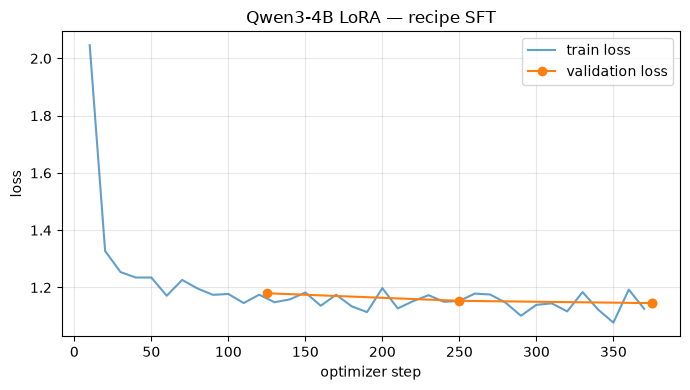

In [14]:
import matplotlib.pyplot as plt

hist = trainer.state.log_history
tr = [(h["step"], h["loss"]) for h in hist if "loss" in h and "eval_loss" not in h]
ev = [(h["step"], h["eval_loss"]) for h in hist if "eval_loss" in h]

plt.figure(figsize=(7, 4))
if tr: plt.plot(*zip(*tr), label="train loss", alpha=0.7)
if ev: plt.plot(*zip(*ev), "o-", label="validation loss")
plt.xlabel("optimizer step"); plt.ylabel("loss"); plt.title("Qwen3-4B LoRA — recipe SFT")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(RESULTS_DIR / "loss_curve.png", dpi=150)
plt.show()

## 10 — Held-out test loss: base vs fine-tuned
Same test examples, same masking (loss on the recipe only). The base model is evaluated by temporarily disabling the LoRA adapter, so no second copy of the model is loaded. Lower perplexity = the model assigns higher probability to real held-out recipes in the target format.

In [15]:
ft_test = trainer.evaluate(test_ds, metric_key_prefix="test")
with model.disable_adapter():
    base_test = trainer.evaluate(test_ds, metric_key_prefix="test")

test_table = pd.DataFrame({
    "Base Qwen3-4B":       [base_test["test_loss"], math.exp(base_test["test_loss"])],
    "Fine-tuned (LoRA)":   [ft_test["test_loss"],   math.exp(ft_test["test_loss"])],
}, index=["test loss", "perplexity"]).round(3)
test_table.to_csv(RESULTS_DIR / "test_loss.csv")
test_table

Training Loss,Validation Loss,Step
1.125509,1.106068,375


Training Loss,Validation Loss,Step
1.125509,2.894508,375


,Base Qwen3-4B,Fine-tuned (LoRA)
test loss,2.895,1.106
perplexity,18.075,3.022


## 11 — Generation evaluation on `diet_eval.jsonl`

Both models generate a recipe for every prompt (greedy decoding). Metrics are computed automatically:

| Metric | How it's measured |
|---|---|
| **Dietary compliance** | The Section 5 classifier runs over the generated ingredients *and* instructions; compliant if the result is allowed for the requested diet |
| **Ingredient coverage** | Share of the user's ingredients that appear in the output |
| **Format completeness** | Has a recipe name, ≥ 2 ingredients and ≥ 2 numbered steps |

The loader accepts common field names (`ingredients`, `preference`/`diet`, `cuisine`; ingredients as a list or comma-separated string). If `diet_eval.jsonl` is missing, it falls back to diet-balanced prompts from the held-out test split. The eval set is only read, never trained on.

In [16]:
from contextlib import nullcontext

def normalize_pref(p):
    p = str(p).lower()
    if "vegan" in p: return "Vegan"
    if "non" in p or "meat" in p: return "Non-Vegetarian"
    if "egg" in p: return "Eggitarian"
    if "veg" in p: return "Vegetarian"
    return "Non-Vegetarian"

def _field(rec, *keys, default=None):
    low = {k.lower(): v for k, v in rec.items()}
    for k in keys:
        if low.get(k) not in (None, "", []):
            return low[k]
    return default

def load_eval_prompts():
    prompts = []
    if EVAL_DATA_PATH.exists():
        with open(EVAL_DATA_PATH) as f:
            records = [json.loads(l) for l in f if l.strip()]
        print(f"Loaded {len(records)} records from {EVAL_DATA_PATH}; keys of first: {list(records[0].keys())}")
        for r in records:
            ings = _field(r, "ingredients", "available_ingredients", "input_ingredients", default=[])
            if isinstance(ings, str):
                ings = [x.strip() for x in ings.split(",") if x.strip()]
            pref = normalize_pref(_field(r, "preference", "diet", "dietary_preference",
                                         "dietary_attribute", "diet_type", default="Non-Vegetarian"))
            cuisine = _field(r, "cuisine", default="General")
            raw = _field(r, "prompt", "instruction", "input", "query")
            user = build_user_message(ings, pref, cuisine) if ings else str(raw)
            prompts.append({"user": user, "ingredients": ings, "preference": pref})
    else:
        print(f"{EVAL_DATA_PATH} not found — using held-out test-split prompts instead.")
        per = 8
        for d in DIETS:
            for _, row in test_df[test_df.dietary_attribute == d].sample(per, random_state=SEED).iterrows():
                ings = given_ingredients(row)
                prompts.append({"user": build_user_message(ings, d, row["cuisine"]),
                                "ingredients": ings, "preference": d})
    return prompts[:N_GEN_EVAL] if N_GEN_EVAL else prompts

@torch.no_grad()
def generate_texts(user_msgs, use_adapter=True, max_new_tokens=GEN_MAX_NEW_TOKENS, batch_size=GEN_BATCH_SIZE):
    model.eval()
    tokenizer.padding_side = "left"
    outs = []
    ctx = nullcontext() if use_adapter else model.disable_adapter()
    with ctx:
        for i in range(0, len(user_msgs), batch_size):
            texts = [chat_prompt(u) for u in user_msgs[i:i + batch_size]]
            enc = tokenizer(texts, return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
            gen = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False,
                                 repetition_penalty=1.05, eos_token_id=EOS_IDS,
                                 pad_token_id=tokenizer.pad_token_id, use_cache=True)
            for row in gen[:, enc["input_ids"].shape[1]:]:
                t = tokenizer.decode(row, skip_special_tokens=True)
                outs.append(re.sub(r"<think>.*?</think>", "", t, flags=re.S).strip())
    tokenizer.padding_side = "right"
    return outs

def parse_recipe(text):
    name = re.search(r"Recipe Name:\s*(.+)", text)
    ing_block = re.search(r"Ingredients:\s*\n(.*?)(?:\n\s*\n|\n\s*Instructions:|\Z)", text, re.S)
    step_block = re.search(r"Instructions:\s*\n(.*)", text, re.S)
    ingredients = [re.sub(r"^\s*[-*•]\s*", "", l).strip() for l in (ing_block.group(1).splitlines() if ing_block else [])
                   if re.match(r"^\s*[-*•]\s+", l)]
    steps = [re.sub(r"^\s*\d+[.)]\s*", "", l).strip() for l in (step_block.group(1).splitlines() if step_block else [])
             if re.match(r"^\s*\d+[.)]\s+", l)]
    return {"name": name.group(1).strip() if name else None, "ingredients": ingredients, "steps": steps}

def ingredient_used(ing, text):
    ing, text = ing.lower().strip(), text.lower()
    if ing in text:
        return True
    head = re.sub(r"e?s$", "", ing.split()[-1]) if ing.split() else ing
    return len(head) > 2 and head in text

def score(prompt, text):
    rec = parse_recipe(text)
    items = rec["ingredients"] + rec["steps"]
    if not items:   # model ignored the format: check every sentence of the raw text
        items = [s for s in re.split(r"[\n.;]", text) if s.strip()]
    produced = classify_items(items)
    cov = (np.mean([ingredient_used(i, text) for i in prompt["ingredients"]])
           if prompt["ingredients"] else np.nan)
    return {
        "compliant": produced in ALLOWED[prompt["preference"]],
        "produced_diet": produced,
        "coverage": cov,
        "format_ok": bool(rec["name"]) and len(rec["ingredients"]) >= 2 and len(rec["steps"]) >= 2,
        "violations": {k: sorted(v) for k, v in detect_animal_products(items).items() if v},
    }

eval_prompts = load_eval_prompts()
users = [p["user"] for p in eval_prompts]
print(f"Generating for {len(users)} prompts x 2 models ...")

t0 = time.time(); base_out = generate_texts(users, use_adapter=False); print(f"base done in {time.time()-t0:.0f}s")
t0 = time.time(); ft_out   = generate_texts(users, use_adapter=True);  print(f"fine-tuned done in {time.time()-t0:.0f}s")

rows = []
for p, b, f in zip(eval_prompts, base_out, ft_out):
    sb, sf = score(p, b), score(p, f)
    rows.append({"preference": p["preference"], "ingredients": ", ".join(p["ingredients"]),
                 "base_output": b, "ft_output": f,
                 **{f"base_{k}": v for k, v in sb.items()}, **{f"ft_{k}": v for k, v in sf.items()}})
gen_df = pd.DataFrame(rows)
gen_df.to_json(RESULTS_DIR / "generation_eval.jsonl", orient="records", lines=True)

summary = pd.DataFrame({
    "Base Qwen3-4B":     [gen_df.base_compliant.mean(), gen_df.base_coverage.mean(), gen_df.base_format_ok.mean()],
    "Fine-tuned (LoRA)": [gen_df.ft_compliant.mean(),   gen_df.ft_coverage.mean(),   gen_df.ft_format_ok.mean()],
}, index=["Dietary compliance", "Ingredient coverage", "Format completeness"])
summary.to_csv(RESULTS_DIR / "generation_eval_summary.csv")
print(f"\nn = {len(gen_df)} prompts")
(summary * 100).round(1).astype(str) + "%"

Loaded 33 records from <project>/data/diet_eval.jsonl; keys of first: ['instruction', 'input', 'expected_diet']
Generating for 33 prompts x 2 models ...
base done in 152s
fine-tuned done in 147s

n = 33 prompts


,Base Qwen3-4B,Fine-tuned (LoRA)
Dietary compliance,100.0%,100.0%
Ingredient coverage,NaN,NaN
Format completeness,66.7%,97.0%


In [17]:
# Compliance by requested diet, and every violation so you can check them by hand
by_diet = gen_df.groupby("preference")[["base_compliant", "ft_compliant"]].mean().mul(100).round(1)
display(by_diet)

viol = gen_df[~gen_df.ft_compliant | ~gen_df.base_compliant]
for _, r in viol.iterrows():
    print(f"[{r.preference}] {r.ingredients}")
    if not r.base_compliant: print(f"   base -> {r.base_produced_diet}: {r.base_violations}")
    if not r.ft_compliant:   print(f"   ft   -> {r.ft_produced_diet}: {r.ft_violations}")

,base_compliant,ft_compliant
preference,,
Non-Vegetarian,100.0,100.0


In [18]:
# Side-by-side outputs for the first few prompts
for _, r in gen_df.head(3).iterrows():
    print("=" * 90)
    print(f"PROMPT: {r.ingredients} | Preference: {r.preference}")
    print("=" * 90)
    print("\n--- BASE QWEN3-4B ---\n" + r.base_output[:1500])
    print("\n--- FINE-TUNED QWEN3-4B ---\n" + r.ft_output[:1500] + "\n")

PROMPT:  | Preference: Non-Vegetarian

--- BASE QWEN3-4B ---
Recipe Name: Veggie Tomato Rice  
Dietary Preference: Vegan  
Cuisine: Asian-inspired  
Total Time: 30 minutes  

Ingredients:  
- 1 cup rice (brown or white, whichever you have)  
- 2 medium tomatoes, diced  
- 1 onion, finely chopped  
- 2 cloves garlic, minced  
- 1 cup water or vegetable broth  
- 1 tsp soy sauce (or tamari for vegan option)  
- 1 tsp sesame oil (optional, for flavor)  
- 1/2 tsp salt  
- 1/4 tsp black pepper  
- 1/4 tsp ginger powder (optional, for extra flavor)  

Instructions:  
1. Heat a pan over medium heat and add a little oil. Add the chopped onion and sauté until translucent.  
2. Add the minced garlic and cook for another minute.  
3. Stir in the diced tomatoes and cook until softened, about 5 minutes.  
4. Add the soy sauce, salt, pepper, and ginger powder (if using). Mix well.  
5. Add the rice and stir to coat with the sauce.  
6. Pour in the water or vegetable broth, making sure the rice is f

## 12 — Inference function
`generate_recipe()` runs the fine-tuned model and returns the parsed recipe plus the raw text and a compliance check.

In [19]:
def generate_recipe(ingredients, preference="Vegetarian", cuisine="General",
                    max_new_tokens=GEN_MAX_NEW_TOKENS) -> dict:
    preference = normalize_pref(preference)
    text = generate_texts([build_user_message(ingredients, preference, cuisine)],
                          use_adapter=True, max_new_tokens=max_new_tokens)[0]
    rec = parse_recipe(text)
    t = re.search(r"Total Time:\s*(.+)", text)
    produced = classify_items(rec["ingredients"] + rec["steps"]) if rec["ingredients"] else None
    return {
        "Recipe Name": rec["name"],
        "Total Time": t.group(1).strip() if t else None,
        "Ingredients": rec["ingredients"],
        "Instructions": rec["steps"],
        "Diet Check": {"requested": preference, "detected": produced,
                       "compliant": produced in ALLOWED[preference] if produced else None},
        "raw_text": text,
    }

demo = generate_recipe(["tomato", "onion", "garlic", "rice"], preference="Vegetarian", cuisine="Indian")
print(demo["raw_text"])
print("\nDiet check:", demo["Diet Check"])

Recipe Name: Rice And Tomato Curry
Dietary Preference: Vegetarian
Cuisine: Indian
Total Time: 25 min
Ingredients:
- tomato
- onion
- garlic
- ginger
- green chilies
- curry leaves
- oil
- turmeric powder
- cumin seeds
- coriander powder
- garam masala powder
- salt
- rice

Instructions:
1. Heat oil in a pan and add onions, garlic, ginger, green chillies and curry leaves
2. Saute for 3 minutes
3. Add tomatoes and cook till soft
4. Add turmeric, cumin seeds, coriander powder, garam masala and salt
5. Cook for another 3 minutes
6. Add rice and mix well
7. Cover and cook on low heat for 10 minutes
8. Serve hot with rotis

Diet check: {'requested': 'Vegetarian', 'detected': 'Vegan', 'compliant': True}


### Loading the adapter later (e.g. in the app)
```python
from transformers import AutoModelForCausalLM, AutoTokenizer
from peft import PeftModel
import torch

base = AutoModelForCausalLM.from_pretrained("Qwen/Qwen3-4B", dtype=torch.bfloat16, device_map="cuda")
# (inference in bf16 needs ~8.5 GB VRAM; for 4-bit add quantization_config=BitsAndBytesConfig(load_in_4bit=True, ...))
model = PeftModel.from_pretrained(base, "models/qwen3-4b-recipe-lora").eval()
tok = AutoTokenizer.from_pretrained("models/qwen3-4b-recipe-lora")
# build prompts with tok.apply_chat_template(..., add_generation_prompt=True, enable_thinking=False)
# and the same SYSTEM_PROMPT used in training
```

In [20]:
# Optional: merge LoRA into the base weights for a standalone model (≈8 GB on disk).
# Run this LAST — it modifies `model` in place. Not possible with USE_4BIT.
MERGE_AND_SAVE = False
if MERGE_AND_SAVE and not USE_4BIT:
    merged_dir = Path("models/qwen3-4b-recipe-merged")
    merged = model.merge_and_unload()
    merged.config.use_cache = True
    merged.save_pretrained(merged_dir, safe_serialization=True)
    tokenizer.save_pretrained(merged_dir)
    print("Merged model saved to", merged_dir)